# QAOA RF — dataset reale, 5 seed, training approfondito
Adattamento del notebook QAOA originale al dataset `output/split/train_dataset.csv` del notebook Comparing RF. Nessun dato sintetico. **QAOA-inspired supervisionato** (non QAOA canonico di ottimizzazione combinatoria). Le prestazioni non sono garantite: il test rimane indipendente dalla selezione degli iperparametri.

**Nota:** 8 qubit × 4 layer × 5 seed × 1200 step può richiedere molte ore su CPU; iniziare con `SMOKE_TEST=True`, poi disattivarlo.

In [1]:
# Se necessario: %pip install pennylane scikit-learn pandas matplotlib tqdm
from pathlib import Path
import time, json, warnings
import numpy as np
import pandas as pd
import pennylane as qml
from pennylane import numpy as pnp
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve
from tqdm.auto import trange


In [2]:
DATA_PATH = Path('output/split/train_dataset.csv')
OUT = Path('results_qaoa_rf_dataset'); OUT.mkdir(exist_ok=True, parents=True)
FEATURES = ['freq1','noise','max_magnitude','total_gain_db','base_pwr_db','rssi','relpwr_db','avgpwr_db']
TARGET = 'label_encoded'
SEEDS = [42,123,2024,2025,2026]
N_QUBITS = 8                 # 8 feature -> 8 qubit; non aumentare senza motivo
LAYERS = 4                   # provare 3,4,6 tramite validation
STEPS = 1200                # massimo, con early stopping
BATCH_SIZE = 32
LR = 0.015
EVAL_EVERY = 25
PATIENCE_EVALS = 12
TRAIN_N = 5000
VAL_N = 1000
TEST_N = 5000
RF_TRAIN_N = 20000
CHUNK_SIZE = 150_000
MAX_ROWS_PER_CLASS = 120_000  # reservoir sampling: limita memoria, non è il file intero
SMOKE_TEST = False
if SMOKE_TEST:
    STEPS, TRAIN_N, VAL_N, TEST_N, RF_TRAIN_N = 20, 100, 80, 100, 500
assert DATA_PATH.exists(), f'Dataset non trovato: {DATA_PATH.resolve()}'


## Lettura del CSV da 2 GB senza caricarlo interamente
Reservoir sampling **per classe** con stream del file. I campioni sono estratti prima dello split. Se esistono identificatori di sessione/acquisizione, è preferibile usare uno split per gruppo: lo split per hash delle feature identiche qui riduce solo la duplicazione esatta.

In [3]:
def stream_reservoir(path, cols, label, cap, seed=2026):
    rng = np.random.default_rng(seed)
    buffers = {0: [], 1: []}; seen = {0:0, 1:0}
    for chunk in pd.read_csv(path, usecols=cols+[label], chunksize=CHUNK_SIZE, low_memory=False):
        chunk = chunk.dropna(subset=[label]).copy()
        yy = pd.to_numeric(chunk[label], errors='coerce')
        chunk = chunk.loc[yy.isin([0,1])]
        for row in chunk.itertuples(index=False, name=None):
            y = int(row[-1]); seen[y] += 1
            if len(buffers[y]) < cap: buffers[y].append(row)
            else:
                j = rng.integers(seen[y])
                if j < cap: buffers[y][j] = row
    if min(seen.values()) == 0: raise ValueError(f'Classi non binarie 0/1 o classe assente: {seen}')
    data = pd.DataFrame(buffers[0]+buffers[1], columns=cols+[label])
    return data.sample(frac=1, random_state=seed).reset_index(drop=True), seen

df, counts = stream_reservoir(DATA_PATH, FEATURES, TARGET, MAX_ROWS_PER_CLASS)
print('Righe originali per classe:', counts, '| campione:', df.shape)


Righe originali per classe: {0: 26376000, 1: 26376000} | campione: (240000, 9)


In [4]:
# Split per hash delle feature: evita che vettori identici finiscano in train e test.
# Non sostituisce uno split per sessione/dispositivo quando tali ID sono disponibili.
groups = pd.util.hash_pandas_object(df[FEATURES], index=False).to_numpy()
idx = np.arange(len(df))
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
fitval_idx, test_idx = next(gss.split(idx, df[TARGET], groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=43)
a,b = next(gss2.split(fitval_idx, df[TARGET].iloc[fitval_idx], groups[fitval_idx]))
train_idx, val_idx = fitval_idx[a], fitval_idx[b]
assert not(set(groups[train_idx]) & set(groups[test_idx]))
assert not(set(groups[val_idx]) & set(groups[test_idx]))
assert not(set(groups[train_idx]) & set(groups[val_idx]))

def subset(ix, n, seed):
    y = df[TARGET].iloc[ix].to_numpy(dtype=int)
    if n >= len(ix): return ix
    return train_test_split(ix, train_size=n, stratify=y, random_state=seed)[0]
train_idx = subset(train_idx, max(TRAIN_N,RF_TRAIN_N), 1)
val_idx = subset(val_idx, VAL_N, 2)
test_idx = subset(test_idx, TEST_N, 3)
q_idx = subset(train_idx, TRAIN_N, 4)
imp = SimpleImputer(strategy='median'); scale = StandardScaler()
Xrf_train = scale.fit_transform(imp.fit_transform(df.loc[train_idx,FEATURES].apply(pd.to_numeric, errors='coerce')))
Xq = scale.transform(imp.transform(df.loc[q_idx,FEATURES].apply(pd.to_numeric, errors='coerce')))
Xval = scale.transform(imp.transform(df.loc[val_idx,FEATURES].apply(pd.to_numeric, errors='coerce')))
Xtest = scale.transform(imp.transform(df.loc[test_idx,FEATURES].apply(pd.to_numeric, errors='coerce')))
yrf = df.loc[train_idx,TARGET].to_numpy(dtype=int)
yq = df.loc[q_idx,TARGET].to_numpy(dtype=int)
yval = df.loc[val_idx,TARGET].to_numpy(dtype=int)
ytest = df.loc[test_idx,TARGET].to_numpy(dtype=int)
# Clipping e mappatura angolare, parametri derivati solo dal train.
Xq = np.pi*np.tanh(Xq/2)
Xval = np.pi*np.tanh(Xval/2)
Xtest = np.pi*np.tanh(Xtest/2)
print('Train/val/test:',Xq.shape,Xval.shape,Xtest.shape)


Train/val/test: (5000, 8) (1000, 8) (5000, 8)


## Hamiltoniana RF-aware e QAOA alternato
La matrice di interazione usa correlazioni assolute del solo train; le coppie sono selezionate prima dell'ottimizzazione. Il circuito applica **a ogni layer** un cost unitary ZZ/RZ e un mixer RX. I parametri di embedding non sono adattati al test.

In [5]:
N_QUBITS = min(N_QUBITS, len(FEATURES))
assert N_QUBITS == Xq.shape[1], 'Questa versione usa 1 qubit per feature (8 qubit).'
cor = np.corrcoef(Xq.T)
cor = np.nan_to_num(cor)
pairs = [(i,j) for i in range(N_QUBITS) for j in range(i+1,N_QUBITS)]
# Catena + connessioni più informative (sparse, costo più gestibile)
chain = {(i,i+1) for i in range(N_QUBITS-1)}
extra = sorted((p for p in pairs if p not in chain), key=lambda p: abs(cor[p]), reverse=True)[:N_QUBITS]
EDGES = sorted(chain | set(extra))
COUPLINGS = np.array([np.clip(cor[i,j],-1,1) for i,j in EDGES])
print('Edges:',len(EDGES),EDGES)
# parametro gamma per layer e per edge, beta per layer e per qubit,
# più bias e scala di lettura supervisionati.
N_COST = LAYERS*(N_QUBITS+len(EDGES))
N_MIX = LAYERS*N_QUBITS
N_PARAMS = N_COST+N_MIX+2

dev = qml.device('default.qubit', wires=N_QUBITS)
@qml.qnode(dev, interface='autograd', diff_method='best')
def quantum_readout(weights, x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation='Y')
    k=0
    for layer in range(LAYERS):
        for i in range(N_QUBITS):
            qml.RZ(weights[k], wires=i); k+=1
        for e,(i,j) in enumerate(EDGES):
            qml.IsingZZ(weights[k]*COUPLINGS[e], wires=[i,j]); k+=1
        for i in range(N_QUBITS):
            qml.RX(weights[k], wires=i); k+=1
    return qml.expval(qml.PauliZ(0))

def probability(w, x):
    z = quantum_readout(w, x)
    logit = w[-2] * z + w[-1]
    # Evita pnp.clip: alcune versioni di PennyLane/Autograd non ne
    # supportano la derivazione e producono NotImplementedType.
    return 0.5 * (1.0 + pnp.tanh(0.5 * logit))

def batch_loss(w, xb, yb):
    # Accumula loss scalari: evita pnp.stack(ArrayBox) e tensor misti.
    # BCE con etichette in {-1,+1}: softplus(-t*logit).
    # Per logits moderati la forma log(1+exp(.)) e' stabile.
    total = 0.0
    for x, y in zip(xb, yb):
        z = quantum_readout(w, np.asarray(x, dtype=float))
        logit = w[-2] * z + w[-1]
        target = 2.0 * float(y) - 1.0
        total = total + pnp.log(1.0 + pnp.exp(-target * logit))
    return total / len(yb)

def predict_proba(w, X):
    return np.asarray([float(probability(w,pnp.array(x))) for x in X])


Edges: 15 [(0, 1), (1, 2), (1, 3), (1, 5), (2, 3), (2, 5), (3, 4), (3, 5), (3, 6), (3, 7), (4, 5), (4, 6), (4, 7), (5, 6), (6, 7)]


## Training lungo, mini-batch bilanciati, 5 seed, checkpoint
Si salva il miglior modello in base ad AUROC di validazione. Non si usa il test per scegliere epoche, layer o soglie.

In [6]:
# Smoke test: verifica differenziabilita prima di lanciare i 5 seed.
_test_w = pnp.array(np.r_[np.random.default_rng(42).normal(0,0.12,N_PARAMS-2), 2.0, 0.0], requires_grad=True)
_test_loss = batch_loss(_test_w, Xq[:2], yq[:2])
_test_grad = qml.grad(lambda theta: batch_loss(theta, Xq[:2], yq[:2]))(_test_w)
print('Smoke loss:', float(_test_loss), 'grad norm:', float(np.linalg.norm(np.asarray(_test_grad))))
assert np.all(np.isfinite(np.asarray(_test_grad)))


Smoke loss: 1.946901205906212 grad norm: 1.1543924612487213


In [7]:
def train_one(seed):
    rng=np.random.default_rng(seed)
    init=rng.normal(0,0.12,N_PARAMS)
    init[-2]=2.0; init[-1]=0.0
    w=pnp.array(init,requires_grad=True)
    opt=qml.AdamOptimizer(stepsize=LR)
    pos=np.flatnonzero(yq==1); neg=np.flatnonzero(yq==0)
    best_auc=-np.inf; best=None; wait=0; history=[]
    start=time.time()
    for step in trange(1,STEPS+1,desc=f'QAOA seed {seed}'):
        batch=np.r_[rng.choice(pos,BATCH_SIZE//2,replace=len(pos)<BATCH_SIZE//2),
                    rng.choice(neg,BATCH_SIZE-BATCH_SIZE//2,replace=len(neg)<BATCH_SIZE-BATCH_SIZE//2)]
        rng.shuffle(batch)
        w=opt.step(lambda theta: batch_loss(theta,Xq[batch],yq[batch]),w)
        if step%EVAL_EVERY==0 or step==STEPS:
            pv=predict_proba(w,Xval)
            auc=roc_auc_score(yval,pv)
            history.append({'step':step,'val_auc':auc})
            if auc>best_auc+1e-4:
                best_auc=auc;best=np.array(w,copy=True);wait=0
                np.savez(OUT/f'qaoa_seed_{seed}.npz',weights=best,step=step,val_auc=auc)
            else: wait+=1
            if wait>=PATIENCE_EVALS: break
    return best,history,time.time()-start

results=[]; traces={}
for seed in SEEDS:
    w,history,train_s=train_one(seed)
    traces[seed]=history
    # Soglia fissata a 0.5: niente tuning sul test.
    start=time.time(); prob=predict_proba(pnp.array(w),Xtest);infer_s=time.time()-start
    pred=(prob>=0.5).astype(int)
    results.append(dict(model='QAOA RF-aware',seed=seed,auc=roc_auc_score(ytest,prob),
                        accuracy=accuracy_score(ytest,pred),balanced_accuracy=balanced_accuracy_score(ytest,pred),
                        precision=precision_score(ytest,pred,zero_division=0),
                        recall=recall_score(ytest,pred,zero_division=0),
                        f1=f1_score(ytest,pred,zero_division=0),
                        train_seconds=train_s,infer_seconds=infer_s))
    np.savez_compressed(OUT/f'qaoa_predictions_{seed}.npz',y=ytest,proba=prob)
    pd.DataFrame(history).to_csv(OUT/f'qaoa_history_{seed}.csv',index=False)


QAOA seed 42:   0%|          | 0/1200 [00:00<?, ?it/s]

QAOA seed 123:   0%|          | 0/1200 [00:00<?, ?it/s]

QAOA seed 2024:   0%|          | 0/1200 [00:00<?, ?it/s]

QAOA seed 2025:   0%|          | 0/1200 [00:00<?, ?it/s]

QAOA seed 2026:   0%|          | 0/1200 [00:00<?, ?it/s]

## Random Forest di riferimento, stessi split e stesse feature
La RF Small usa lo stesso numero di esempi del QAOA. RF Large usa più dati e va interpretata come confronto aggiuntivo, non a parità di campioni.

                  auc              f1          recall          \
                 mean     std    mean     std    mean     std   
model                                                           
QAOA RF-aware  0.9922  0.0020  0.9601  0.0074  0.9719  0.0100   
RF Large       0.9988  0.0000  0.9845  0.0003  0.9881  0.0007   
RF Small       0.9981  0.0001  0.9787  0.0012  0.9858  0.0024   

              balanced_accuracy         train_seconds            
                           mean     std          mean       std  
model                                                            
QAOA RF-aware            0.9590  0.0078     3587.8996  214.2833  
RF Large                 0.9842  0.0003        2.6273    0.0398  
RF Small                 0.9782  0.0012        1.5876    0.0326  


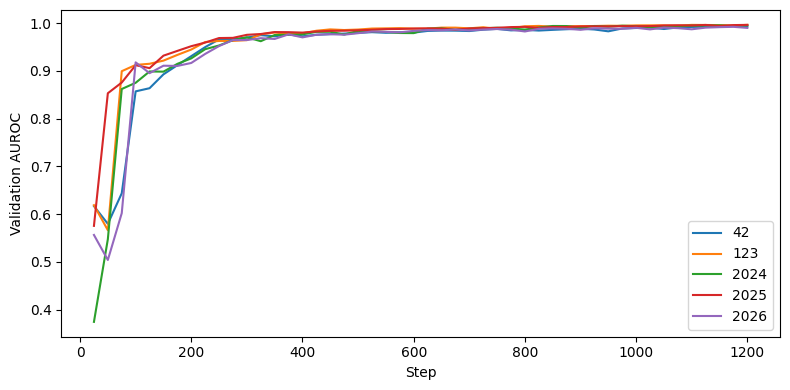

In [8]:
for seed in SEEDS:
    for name,nrows in [('RF Small',TRAIN_N),('RF Large',RF_TRAIN_N)]:
        ids=np.arange(len(yrf))
        if nrows<len(ids): ids=train_test_split(ids,train_size=nrows,stratify=yrf,random_state=seed)[0]
        t0=time.time()
        rf=RandomForestClassifier(n_estimators=300,min_samples_leaf=2,n_jobs=-1,random_state=seed,class_weight='balanced_subsample')
        rf.fit(Xrf_train[ids],yrf[ids]);train_s=time.time()-t0
        # RF opera sulle feature standardizzate, non sugli angoli del QAOA.
        Xt=scale.transform(imp.transform(df.loc[test_idx,FEATURES].apply(pd.to_numeric,errors='coerce')))
        t0=time.time();prob=rf.predict_proba(Xt)[:,1];infer_s=time.time()-t0
        pred=(prob>=0.5).astype(int)
        results.append(dict(model=name,seed=seed,auc=roc_auc_score(ytest,prob),accuracy=accuracy_score(ytest,pred),
                            balanced_accuracy=balanced_accuracy_score(ytest,pred),
                            precision=precision_score(ytest,pred,zero_division=0),recall=recall_score(ytest,pred,zero_division=0),
                            f1=f1_score(ytest,pred,zero_division=0),train_seconds=train_s,infer_seconds=infer_s))
res=pd.DataFrame(results)
res.to_csv(OUT/'metrics_5_seeds.csv',index=False)
print(res.groupby('model')[['auc','f1','recall','balanced_accuracy','train_seconds']].agg(['mean','std']).round(4))
plt.figure(figsize=(8,4))
for seed,h in traces.items(): plt.plot([v['step'] for v in h],[v['val_auc'] for v in h],label=str(seed))
plt.xlabel('Step');plt.ylabel('Validation AUROC');plt.legend();plt.tight_layout();plt.savefig(OUT/'validation_auc.png',dpi=150);plt.show()


## Interpretazione e sviluppi
- **Più layer/qubit non significa automaticamente migliore generalizzazione.** Con 8 feature, 8 qubit sono una scelta naturale; per 10–12 qubit occorrono nuove feature legittime o una codifica motivata, non duplicazioni arbitrarie.
- Provare `LAYERS = 3, 4, 6` **solo sulla validation**; scegliere una configurazione e rifare il confronto sul test senza consultarlo durante il tuning.
- Le 5 inizializzazioni non equivalgono a 5 dataset indipendenti: il test è fisso; per stimare variabilità dei dati servono split multipli raggruppati.
- Se il dataset contiene identificativi di acquisizione, usare `GroupShuffleSplit` con quelli anziché il solo hash delle feature.
- Questa è una variante **QAOA-inspired** supervisionata con cost layers trainabili; non dimostra vantaggio quantistico. Registrare versione PennyLane, hardware e tempi.
